<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 23 · Non-equilibrium Green's functions at finite bias

Linear-response transport (tutorials 08–12) needs only $T(E_F)$. At finite bias the leads sit at different
chemical potentials $\mu_L=\mu+V/2$, $\mu_R=\mu-V/2$, and the device is out of equilibrium:

$$G^<=i\sum_\alpha f_\alpha\,G\Gamma_\alpha G^\dagger,\qquad n_i=\int\frac{dE}{2\pi}\sum_\alpha f_\alpha[G\Gamma_\alpha G^\dagger]_{ii},\qquad
I=\frac{e}{h}\int dE\,T(E,V)\,[f_L-f_R].$$

`hf.transport.negf.solve` computes the density, the current, bond currents and, optionally, a **self-consistent
electrostatic potential** at the Hartree level, $\phi_i=U_H(n_i-n_i^0)+\phi^{\rm ext}_i$. The equilibrium part of
the density is integrated on a complex contour, so bound states are included.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import transport as tr

## 1 · A single resonant level
A dot site (energy ε₀) is weakly coupled to two chains. The current switches on when $\mu_L=V/2$ crosses ε₀, so $dI/dV$ peaks at $V=2\varepsilon_0$. The saturated current is $\pi\Gamma$ (wide-band Breit-Wigner).

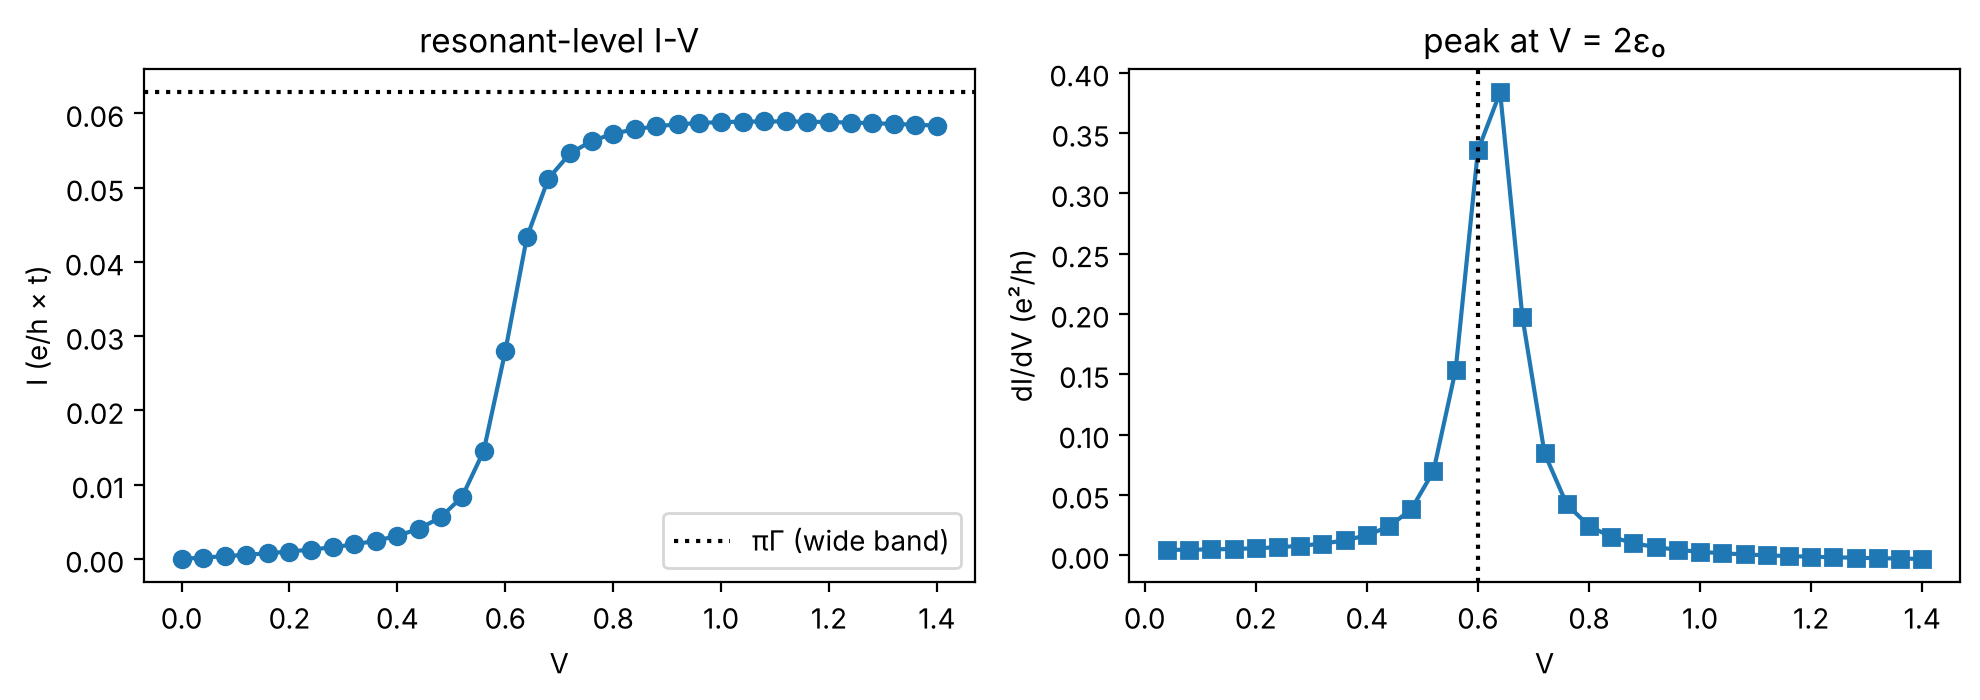

In [2]:
L, c, tp, eps0 = 11, 5, 0.1, 0.3
hop = lambda ri, rj, T: T * tp if sorted([round(ri[0]), round(rj[0])]) in ([c - 1, c], [c, c + 1]) else T
dot = tr.System(hf.models.chain(), lambda r: 0 <= r[0] < L, hopping=hop,
                onsite=lambda pos, name: eps0 if round(pos[0]) == c else 0.0)
dot.attach_lead((-1,)); dot.attach_lead((1,))
Vs = np.linspace(0, 1.4, 36)
I = [tr.negf.solve(dot, V, profile="flat", kT=0.005, n_energy=401, currents=False).current for V in Vs]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(Vs, I, "o-"); ax[0].axhline(np.pi * 2 * tp**2, c="k", ls=":", label="πΓ (wide band)")
ax[0].set_xlabel("V"); ax[0].set_ylabel("I (e/h × t)"); ax[0].legend(); ax[0].set_title("resonant-level I-V")
ax[1].plot(Vs[1:], np.diff(I) / np.diff(Vs), "s-"); ax[1].axvline(2 * eps0, c="k", ls=":")
ax[1].set_xlabel("V"); ax[1].set_ylabel("dI/dV (e²/h)"); ax[1].set_title("peak at V = 2ε₀")
plt.tight_layout()

## 2 · Resonant-tunnelling diode: negative differential resistance
Two barriers define a quantum well. Under bias the potential drops linearly, which drags the well level down. The current peaks when the level aligns with the emitter states, then falls. The Hartree term $U_H$ makes the potential self-consistent: charge in the well raises its energy and shifts the peak.

Text(0.5, 1.0, 'double-barrier RTD: peak and NDR')

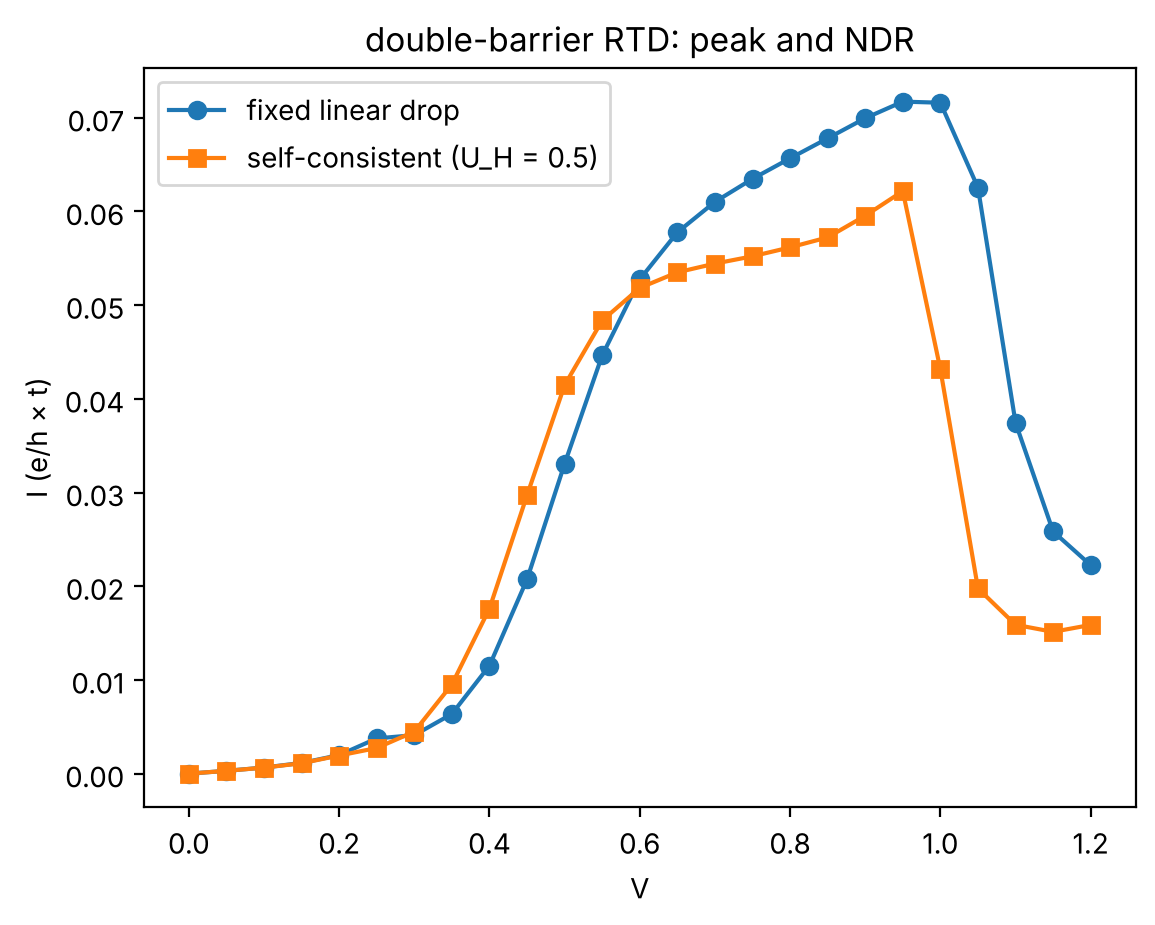

In [3]:
Lr = 30
def rtd_onsite(pos, name):
    x = round(pos[0])
    return 1.0 if x in (10, 11, 18, 19) else 0.0
rtd = tr.System(hf.models.chain(), lambda r: 0 <= r[0] < Lr, onsite=rtd_onsite)
rtd.attach_lead((-1,)); rtd.attach_lead((1,))
mu = -1.7
Vs = np.linspace(0.0, 1.2, 25)
V, I0 = tr.negf.iv(rtd, Vs, mu=mu, kT=0.02, n_energy=161, n_jobs=-1)
V, I1 = tr.negf.iv(rtd, Vs, mu=mu, kT=0.02, n_energy=161, hartree=0.5, n_jobs=-1)
plt.plot(V, I0, "o-", label="fixed linear drop")
plt.plot(V, I1, "s-", label="self-consistent (U_H = 0.5)")
plt.xlabel("V"); plt.ylabel("I (e/h × t)"); plt.legend(); plt.title("double-barrier RTD: peak and NDR")

iterations: 28  converged: True


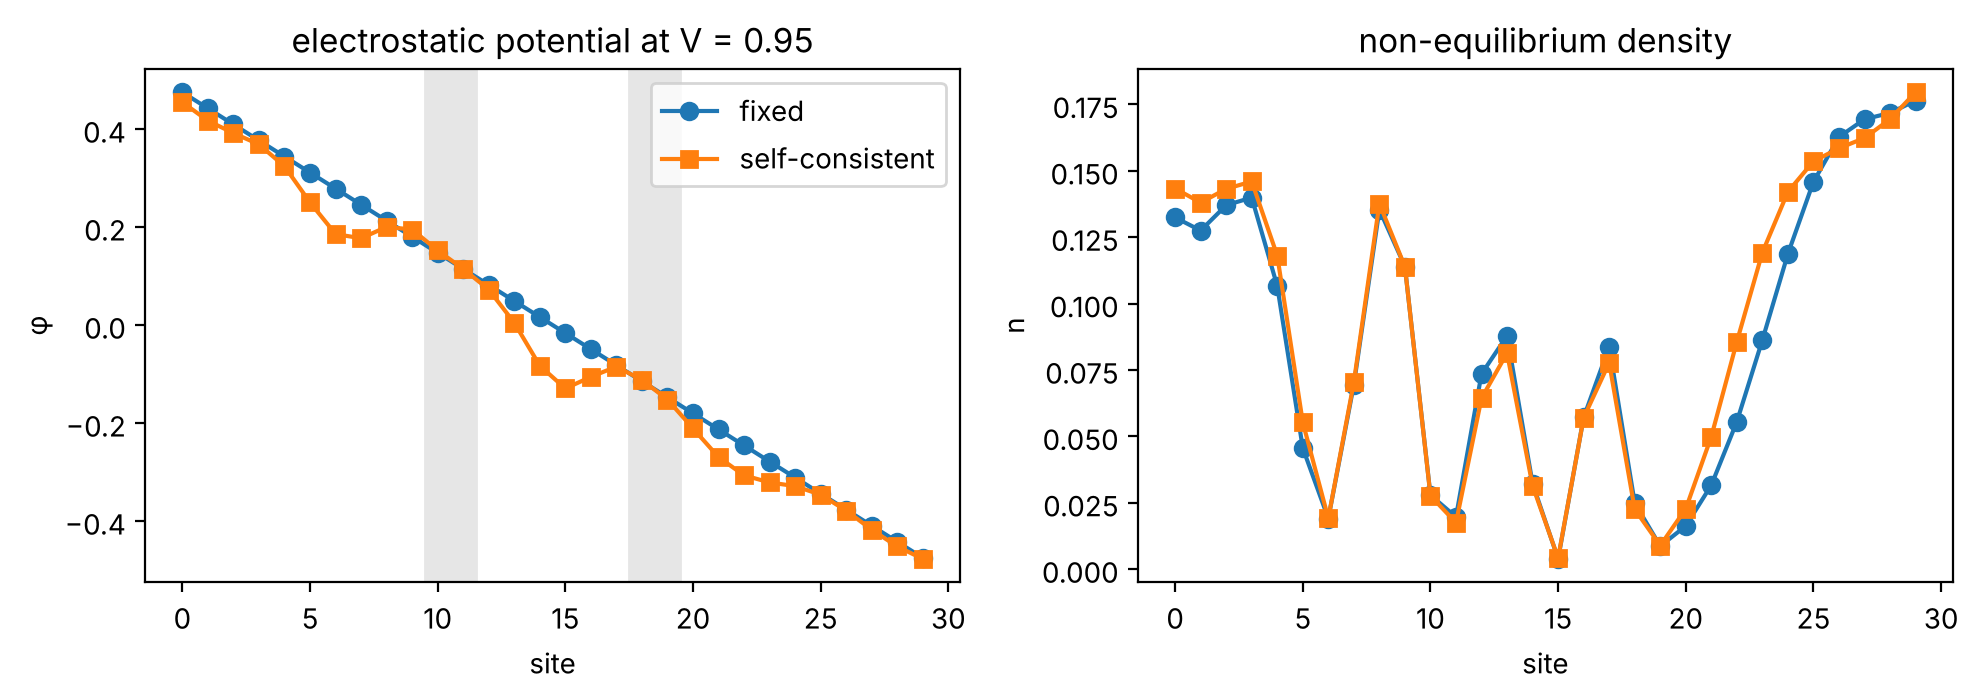

In [4]:
Vp = V[np.argmax(I1)]
r_lin = tr.negf.solve(rtd, Vp, mu=mu, kT=0.02, n_energy=161, currents=False)
r_sc = tr.negf.solve(rtd, Vp, mu=mu, kT=0.02, n_energy=161, hartree=0.5, currents=False)
x = np.arange(Lr)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(x, r_lin.site_potential(), "o-", label="fixed"); ax[0].plot(x, r_sc.site_potential(), "s-", label="self-consistent")
for b in (10, 11, 18, 19): ax[0].axvspan(b - 0.5, b + 0.5, color="0.9")
ax[0].set_xlabel("site"); ax[0].set_ylabel("φ"); ax[0].legend(); ax[0].set_title(f"electrostatic potential at V = {Vp:.2f}")
ax[1].plot(x, r_lin.site_density(), "o-"); ax[1].plot(x, r_sc.site_density(), "s-")
ax[1].set_xlabel("site"); ax[1].set_ylabel("n"); ax[1].set_title("non-equilibrium density")
plt.tight_layout(); print("iterations:", r_sc.iterations, " converged:", r_sc.converged)

## 3 · Bond currents at finite bias in a disordered conductor
Current flows around strong scatterers. Summed over any cross-section, the bond currents equal the Landauer current to machine precision.

current through every cross-section: [0.74028476 0.74028553]


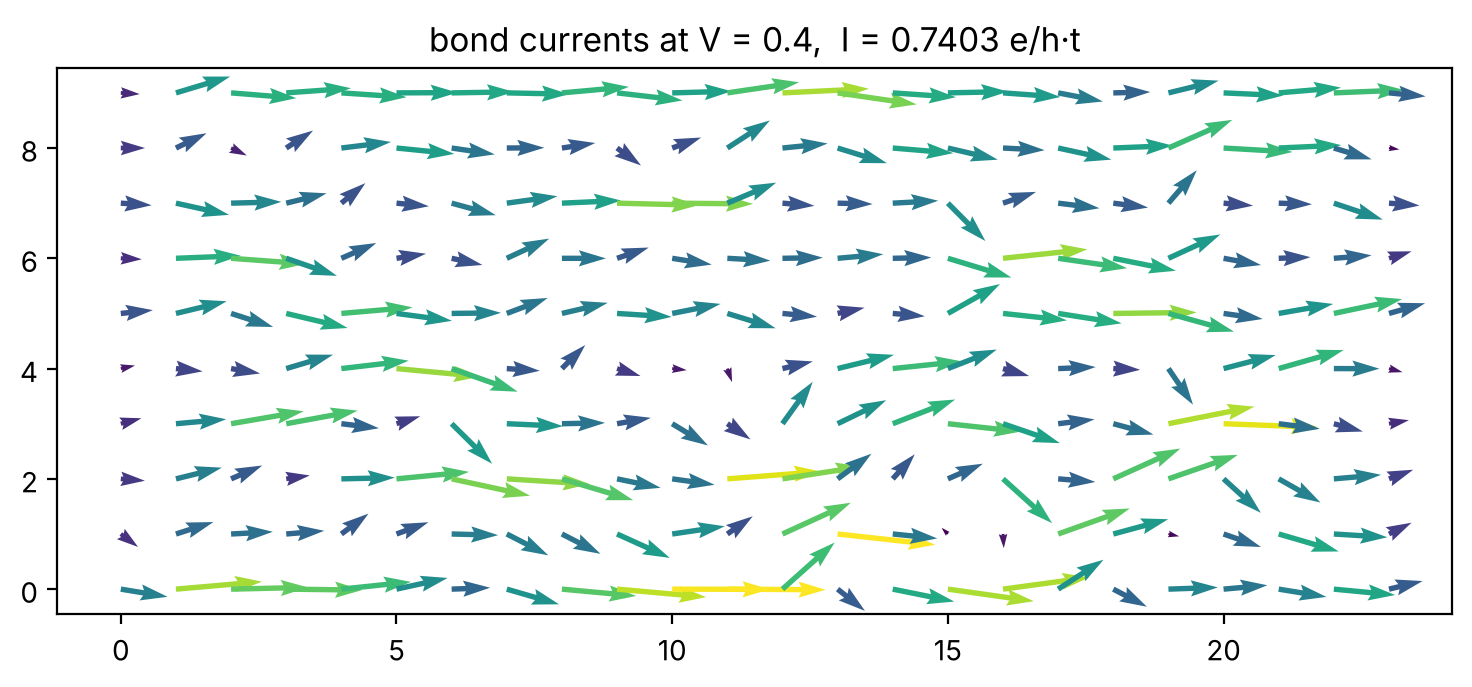

In [5]:
strip = tr.System(hf.models.square(), lambda r: 0 <= r[0] < 24 and 0 <= r[1] < 10, onsite=tr.anderson(2.0, seed=7))
strip.attach_lead((-1, 0)); strip.attach_lead((1, 0))
res = tr.negf.solve(strip, bias=0.4, mu=-1.0, kT=0.01, n_energy=81)
P = strip.positions()
Jx, Jy = np.zeros(len(P)), np.zeros(len(P))
for (a, b), j in zip(res.bonds, res.bond_currents):
    d = P[b] - P[a]
    for s_ in (a, b):
        Jx[s_] += 0.5 * j * d[0]; Jy[s_] += 0.5 * j * d[1]
plt.figure(figsize=(9, 4))
plt.quiver(P[:, 0], P[:, 1], Jx, Jy, np.hypot(Jx, Jy), cmap="viridis", scale_units="xy")
plt.gca().set_aspect("equal"); plt.title(f"bond currents at V = 0.4,  I = {res.current:.4f} e/h·t")
cuts = []
for xc in range(23):
    cuts.append(sum(np.sign(P[b][0] - P[a][0]) * j for (a, b), j in zip(res.bonds, res.bond_currents)
                    if min(P[a][0], P[b][0]) <= xc + 0.5 < max(P[a][0], P[b][0])))
print("current through every cross-section:", np.round([min(cuts), max(cuts)], 8))

## 4 · Linear-response limit
At small bias, $dI/dV$ must reduce to the Landauer conductance $T(\mu)$.

In [6]:
for mu_ in (-0.2, 0.0, 0.05, 0.3):
    G = tr.negf.differential_conductance(dot, 0.0, dV=2e-4, mu=mu_, profile="flat", n_energy=41)
    print(f"mu = {mu_:+.2f}:  dI/dV = {G:.6f}   T(mu) = {dot.smatrix(mu_).transmission(1, 0):.6f}")

mu = -0.20:  dI/dV = 0.001594   T(mu) = 0.001594


mu = +0.00:  dI/dV = 0.004425   T(mu) = 0.004425
mu = +0.05:  dI/dV = 0.006330   T(mu) = 0.006330


mu = +0.30:  dI/dV = 0.977497   T(mu) = 0.977500


## Summary
* `negf.solve(system, bias, ...)` gives the current, non-equilibrium density, potential and bond currents.
* `hartree=U_H` (or `coulomb=matrix`) makes the electrostatics self-consistent; `iv(...)` runs bias sweeps in parallel.
* Checks: exact Breit-Wigner integral, current conservation, linear-response limit (benchmarks).
* Energies in eV give amperes via `result.current_A`.

---
## Quiz 23: Finite-bias NEGF

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [7]:
quiz = hf.Quiz(23)
quiz.interactive()

In [8]:
quiz.show()

=== Quiz 23: Non-equilibrium Green's functions at finite bias ===

Q1. At finite bias V the two leads have
   (a) different chemical potentials mu +- V/2
   (b) the same chemical potential
   (c) infinite temperature
   (d) no Fermi functions

Q2. The lesser Green's function is
   (a) G< = G^r - G^a
   (b) G< = i sum_a f_a G Gamma_a G^dagger
   (c) G< = 0
   (d) G< = Gamma

Q3. The non-equilibrium density is
   (a) T(E)
   (b) n_i = int dE/2pi sum_a f_a [G Gamma_a G^dag]_ii
   (c) -Im G/pi at mu only
   (d) the equilibrium density

Q4. The Landauer current at finite bias is
   (a) I = V/R
   (b) I = (e/h) int dE T(E, V) [f_L - f_R]
   (c) I = G V always
   (d) I = 0

Q5. hopforge integrates the equilibrium part of the density on a complex contour because
   (a) G is smooth there and bound states are included
   (b) for plotting
   (c) real-axis integration is exact
   (d) it is required by the leads

Q6. The Hartree self-consistency in `negf.solve(hartree=U_H)` sets
   (a) phi = 0
   (

In [9]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0